In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [2]:
print("Dossier actuel :", os.getcwd())

Dossier actuel : C:\Users\DELL\Desktop\Azza_Khechine\FraudDetectionXAI


In [3]:
import os

if os.path.exists("data/raw/train_transaction.csv"):
    DATA_PATH = "data/raw"
elif os.path.exists("../data/raw/train_transaction.csv"):
    DATA_PATH = "../data/raw"
else:
    DATA_PATH = None

print("Chemin des données :", DATA_PATH)

Chemin des données : data/raw


In [4]:
TRANSACTION_FILE = os.path.join(DATA_PATH, "train_transaction.csv")

df_sample = pd.read_csv(TRANSACTION_FILE, nrows=5)

display(df_sample)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
# Initialisation des compteurs
total_transactions = 0

fraud_counts = {
    0: 0,
    1: 0
}

# Lecture du fichier par blocs de 100 000 lignes
for chunk in pd.read_csv(
    TRANSACTION_FILE,
    usecols=["isFraud", "TransactionAmt"],
    chunksize=100_000
):
    total_transactions += len(chunk)

    # Compter les transactions normales et frauduleuses
    counts = chunk["isFraud"].value_counts()

    for classe in [0, 1]:
        fraud_counts[classe] += counts.get(classe, 0)

# Construire un tableau récapitulatif
df_classes = pd.DataFrame({
    "Type de transaction": ["Normale", "Frauduleuse"],
    "Nombre": [
        fraud_counts[0],
        fraud_counts[1]
    ]
})

df_classes["Pourcentage"] = (
    df_classes["Nombre"] / total_transactions * 100
)

display(df_classes)

print("Nombre total de transactions :", total_transactions)
print("Taux de fraude :", round(
    fraud_counts[1] / total_transactions * 100, 3
), "%")

,Type de transaction,Nombre,Pourcentage
0,Normale,569877,96.500999
1,Frauduleuse,20663,3.499001


Nombre total de transactions : 590540
Taux de fraude : 3.499 %


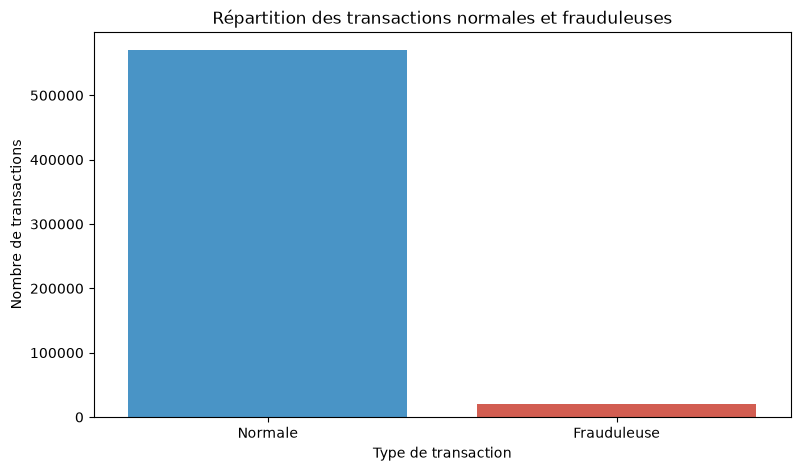

In [6]:
# Définir la taille du graphique
plt.figure(figsize=(9, 5))

# Créer le graphique en barres
sns.barplot(
    data=df_classes,
    x="Type de transaction",
    y="Nombre",
    hue="Type de transaction",
    palette=["#3498db", "#e74c3c"],
    legend=False
)

# Ajouter le titre et les noms des axes
plt.title("Répartition des transactions normales et frauduleuses")
plt.xlabel("Type de transaction")
plt.ylabel("Nombre de transactions")

# Afficher le graphique
plt.show()

In [7]:
# Définir le nombre de transactions à sélectionner
SAMPLE_SIZE = 50000

# Sélectionner uniquement les colonnes nécessaires
df_amount_sample = pd.read_csv(
    TRANSACTION_FILE,
    usecols=["TransactionID", "isFraud", "TransactionAmt"],
    dtype={
        "TransactionID": "int32",
        "isFraud": "int8",
        "TransactionAmt": "float32"
    }
)

# Sélectionner un échantillon aléatoire reproductible
df_amount_sample = df_amount_sample.sample(
    n=SAMPLE_SIZE,
    random_state=42
)

# Afficher les premières lignes
display(df_amount_sample.head())

print("Nombre de transactions sélectionnées :", len(df_amount_sample))

,TransactionID,isFraud,TransactionAmt
470624,3457624,0,724.000000
565820,3552820,0,108.500000
284083,3271083,0,47.950001
239689,3226689,0,100.598999
281855,3268855,0,107.949997


Nombre de transactions sélectionnées : 50000


In [8]:
# Calculer les statistiques des montants pour chaque classe
amount_stats = df_amount_sample.groupby("isFraud")["TransactionAmt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Remplacer les codes des classes par des noms
amount_stats.index = ["Normales (0)", "Frauduleuses (1)"]

# Afficher les résultats
display(amount_stats.round(2))

,count,mean,median,std,min,max
Normales (0),48207,135.300003,67.949997,274.089996,0.86,31937.390625
Frauduleuses (1),1793,151.279999,77.000000,247.449997,0.35,5191.000000


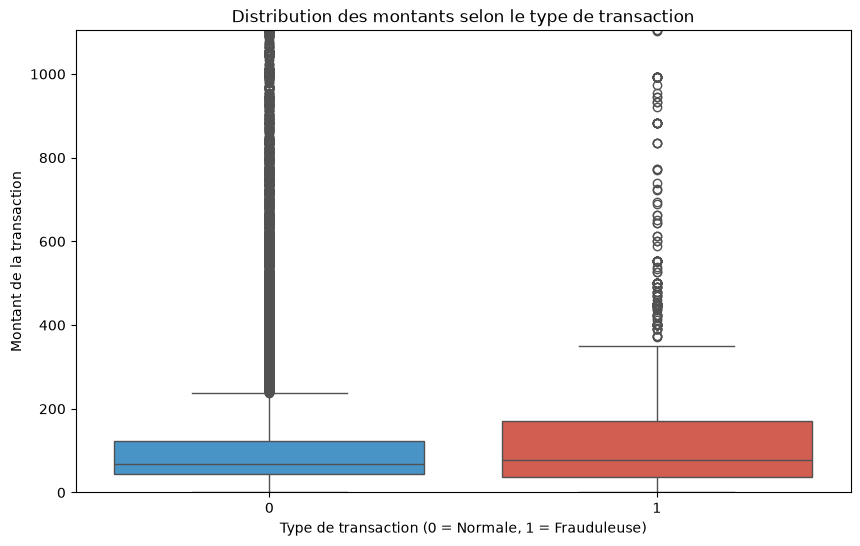

In [9]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_amount_sample,
    x="isFraud",
    y="TransactionAmt",
    hue="isFraud",
    palette={0: "#3498db", 1: "#e74c3c"},
    legend=False
)

plt.title("Distribution des montants selon le type de transaction")
plt.xlabel("Type de transaction (0 = Normale, 1 = Frauduleuse)")
plt.ylabel("Montant de la transaction")

plt.ylim(0, df_amount_sample["TransactionAmt"].quantile(0.99))

plt.show()

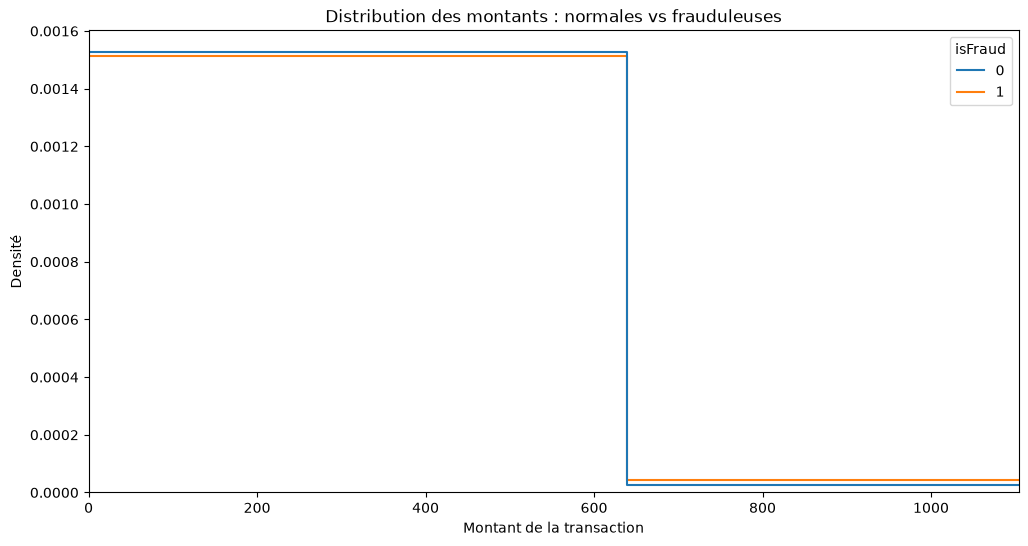

In [10]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_amount_sample,
    x="TransactionAmt",
    hue="isFraud",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Distribution des montants : normales vs frauduleuses")
plt.xlabel("Montant de la transaction")
plt.ylabel("Densité")

plt.xlim(0, df_amount_sample["TransactionAmt"].quantile(0.99))

plt.show()

In [11]:
# Lire uniquement les colonnes nécessaires
df_time = pd.read_csv(
    TRANSACTION_FILE,
    usecols=["TransactionID", "TransactionDT", "isFraud"],
    dtype={
        "TransactionID": "int32",
        "TransactionDT": "int32",
        "isFraud": "int8"
    }
)

# Afficher les premières transactions
display(df_time.head())

# Afficher les informations générales
print("Nombre de transactions :", len(df_time))

print("Temps minimum :", df_time["TransactionDT"].min())

print("Temps maximum :", df_time["TransactionDT"].max())

print("Durée totale en jours :",
      round(
          (df_time["TransactionDT"].max() -
           df_time["TransactionDT"].min()) / 86400,
          2
      ))

,TransactionID,isFraud,TransactionDT
0,2987000,0,86400
1,2987001,0,86401
2,2987002,0,86469
3,2987003,0,86499
4,2987004,0,86506


Nombre de transactions : 590540
Temps minimum : 86400
Temps maximum : 15811131
Durée totale en jours : 182.0


In [12]:
# Calculer le nombre de jours écoulés
df_time["TransactionDay"] = (
    df_time["TransactionDT"] // 86400
)

# Afficher les premières lignes
display(
    df_time[
        ["TransactionDT", "TransactionDay", "isFraud"]
    ].head(10)
)

,TransactionDT,TransactionDay,isFraud
0,86400,1,0
1,86401,1,0
2,86469,1,0
3,86499,1,0
4,86506,1,0
5,86510,1,0
6,86522,1,0
7,86529,1,0
8,86535,1,0
9,86536,1,0


In [13]:
# Regrouper les transactions par jour
daily_stats = df_time.groupby("TransactionDay").agg(
    Total_Transactions=("isFraud", "count"),
    Total_Fraudes=("isFraud", "sum")
)

# Calculer le taux de fraude quotidien en pourcentage
daily_stats["Taux_Fraude"] = (
    daily_stats["Total_Fraudes"]
    / daily_stats["Total_Transactions"]
) * 100

# Afficher les premières lignes
display(daily_stats.head(10))

# Afficher quelques statistiques
print("Nombre de jours observés :", len(daily_stats))
print("Taux moyen quotidien :",
      round(daily_stats["Taux_Fraude"].mean(), 2), "%")

,Total_Transactions,Total_Fraudes,Taux_Fraude
TransactionDay,,,
1,5122,112,2.186646
2,3730,123,3.297587
3,3241,92,2.838630
4,4036,115,2.849356
5,3964,127,3.203835
6,3717,99,2.663438
7,3786,136,3.592182
8,3999,93,2.325581
9,3907,119,3.045815


Nombre de jours observés : 182
Taux moyen quotidien : 3.6 %


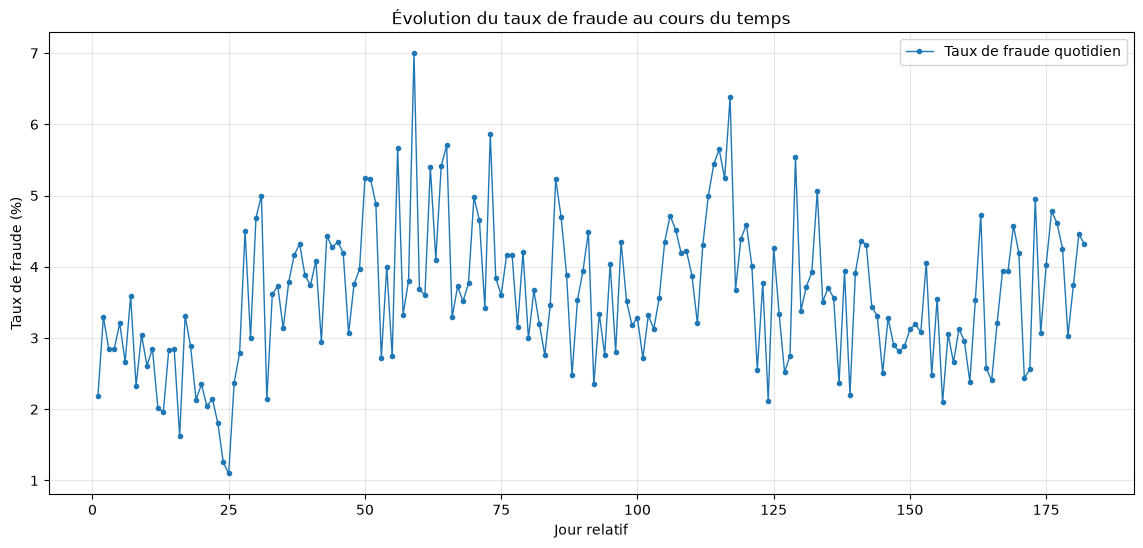

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_stats.index,
    daily_stats["Taux_Fraude"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Taux de fraude quotidien"
)

plt.title("Évolution du taux de fraude au cours du temps")
plt.xlabel("Jour relatif")
plt.ylabel("Taux de fraude (%)")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

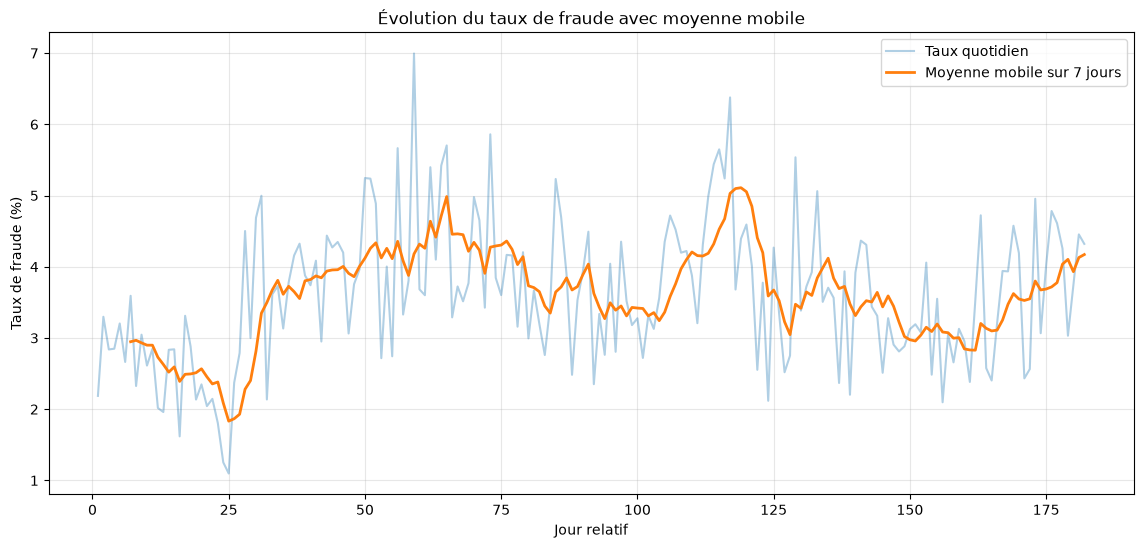

In [15]:
# Calculer la moyenne mobile sur 7 jours
daily_stats["Taux_Fraude_MA7"] = (
    daily_stats["Taux_Fraude"].rolling(window=7).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_stats.index,
    daily_stats["Taux_Fraude"],
    alpha=0.35,
    label="Taux quotidien"
)

plt.plot(
    daily_stats.index,
    daily_stats["Taux_Fraude_MA7"],
    linewidth=2,
    label="Moyenne mobile sur 7 jours"
)

plt.title("Évolution du taux de fraude avec moyenne mobile")
plt.xlabel("Jour relatif")
plt.ylabel("Taux de fraude (%)")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [16]:
df_categories = pd.read_csv(
    TRANSACTION_FILE,
    usecols=["ProductCD", "card4", "isFraud"]
)

display(df_categories.head())

print("Nombre de lignes :", len(df_categories))

,isFraud,ProductCD,card4
0,0,W,discover
1,0,W,mastercard
2,0,W,visa
3,0,W,mastercard
4,0,H,mastercard


Nombre de lignes : 590540


In [17]:
product_stats = df_categories.groupby("ProductCD").agg(
    Total_Transactions=("isFraud", "count"),
    Total_Fraudes=("isFraud", "sum")
)

product_stats["Taux_Fraude"] = (
    product_stats["Total_Fraudes"]
    / product_stats["Total_Transactions"]
) * 100

product_stats = product_stats.sort_values(
    by="Taux_Fraude",
    ascending=False
)

display(product_stats.round(2))

,Total_Transactions,Total_Fraudes,Taux_Fraude
ProductCD,,,
C,68519,8008,11.69
S,11628,686,5.90
H,33024,1574,4.77
R,37699,1426,3.78
W,439670,8969,2.04


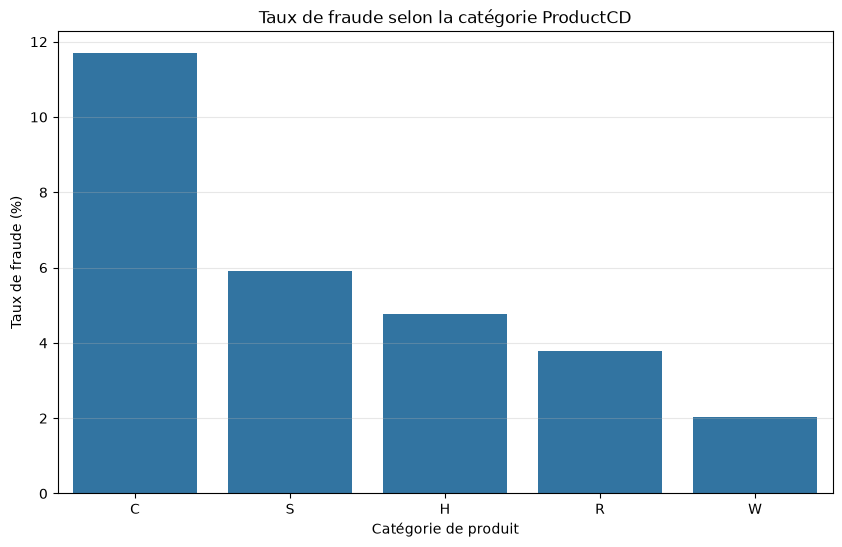

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_stats.reset_index(),
    x="ProductCD",
    y="Taux_Fraude"
)

plt.title("Taux de fraude selon la catégorie ProductCD")
plt.xlabel("Catégorie de produit")
plt.ylabel("Taux de fraude (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [19]:
card_stats = df_categories.groupby("card4").agg(
    Total_Transactions=("isFraud", "count"),
    Total_Fraudes=("isFraud", "sum")
)

card_stats["Taux_Fraude"] = (
    card_stats["Total_Fraudes"]
    / card_stats["Total_Transactions"]
) * 100

card_stats = card_stats.sort_values(
    by="Taux_Fraude",
    ascending=False
)

display(card_stats.round(2))

,Total_Transactions,Total_Fraudes,Taux_Fraude
card4,,,
discover,6651,514,7.73
visa,384767,13373,3.48
mastercard,189217,6496,3.43
american express,8328,239,2.87


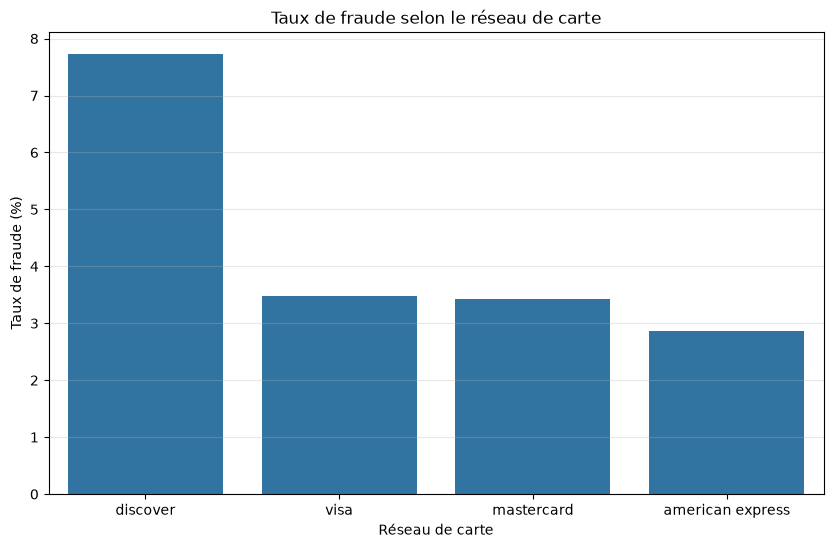

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=card_stats.reset_index(),
    x="card4",
    y="Taux_Fraude"
)

plt.title("Taux de fraude selon le réseau de carte")
plt.xlabel("Réseau de carte")
plt.ylabel("Taux de fraude (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [21]:
# Calculer le nombre de valeurs manquantes par colonne
missing_count = df_categories.isnull().sum()

# Calculer le pourcentage de valeurs manquantes
missing_percentage = (
    missing_count / len(df_categories)
) * 100

# Construire un tableau récapitulatif
missing_stats = pd.DataFrame({
    "Valeurs_manquantes": missing_count,
    "Pourcentage": missing_percentage
})

# Garder uniquement les colonnes qui ont des valeurs manquantes
missing_stats = missing_stats[
    missing_stats["Valeurs_manquantes"] > 0
]

# Trier par pourcentage décroissant
missing_stats = missing_stats.sort_values(
    by="Pourcentage",
    ascending=False
)

display(missing_stats.round(2))

,Valeurs_manquantes,Pourcentage
card4,1577,0.27


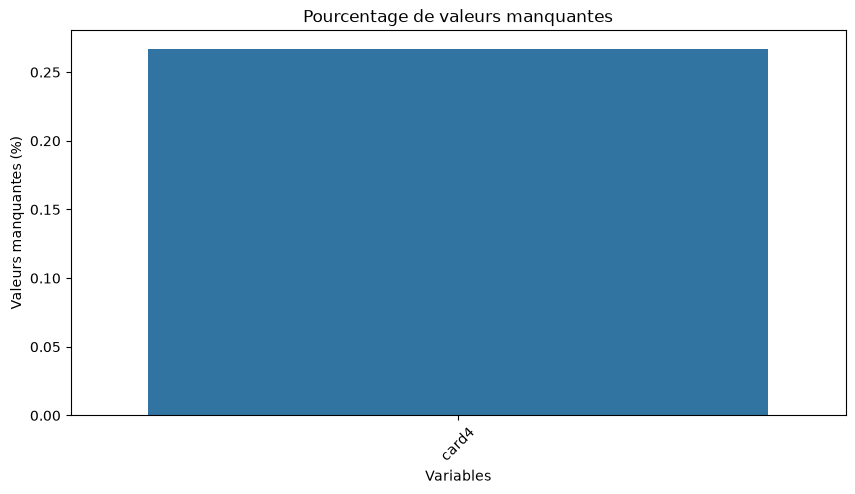

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_stats.index,
    y=missing_stats["Pourcentage"]
)

plt.title("Pourcentage de valeurs manquantes")
plt.xlabel("Variables")
plt.ylabel("Valeurs manquantes (%)")
plt.xticks(rotation=45)

plt.show()

In [23]:
# Initialiser un dictionnaire pour compter les valeurs manquantes
missing_counts_full = {}

# Lire le fichier par morceaux de 100 000 lignes
for chunk in pd.read_csv(
    TRANSACTION_FILE,
    chunksize=100_000
):

    # Compter les valeurs manquantes de chaque colonne
    chunk_missing = chunk.isnull().sum()

    # Additionner les résultats des différents morceaux
    for column, count in chunk_missing.items():
        missing_counts_full[column] = (
            missing_counts_full.get(column, 0) + count
        )

# Construire un DataFrame récapitulatif
missing_full = pd.DataFrame({
    "Valeurs_manquantes": pd.Series(missing_counts_full)
})

# Calculer le pourcentage de valeurs manquantes
missing_full["Pourcentage"] = (
    missing_full["Valeurs_manquantes"] / 590540
) * 100

# Trier par pourcentage décroissant
missing_full = missing_full.sort_values(
    by="Pourcentage",
    ascending=False
)

# Afficher les 20 colonnes les plus concernées
display(missing_full.head(20).round(2))

,Valeurs_manquantes,Pourcentage
dist2,552913,93.63
D7,551623,93.41
D13,528588,89.51
D14,528353,89.47
D12,525823,89.04
D6,517353,87.61
D9,515614,87.31
D8,515614,87.31
V153,508595,86.12
V149,508595,86.12


In [24]:
# Compter les colonnes selon leur pourcentage de valeurs manquantes

nb_sans_manquantes = (
    (missing_full["Pourcentage"] == 0).sum()
)

nb_faibles = (
    (missing_full["Pourcentage"] > 0) &
    (missing_full["Pourcentage"] <= 10)
).sum()

nb_moyennes = (
    (missing_full["Pourcentage"] > 10) &
    (missing_full["Pourcentage"] <= 50)
).sum()

nb_importantes = (
    (missing_full["Pourcentage"] > 50) &
    (missing_full["Pourcentage"] <= 80)
).sum()

nb_tres_importantes = (
    (missing_full["Pourcentage"] > 80)
).sum()

# Construire un tableau récapitulatif
missing_distribution = pd.DataFrame({
    "Niveau de valeurs manquantes": [
        "Aucune",
        "De 0 à 10 %",
        "De 10 à 50 %",
        "De 50 à 80 %",
        "Plus de 80 %"
    ],
    "Nombre de colonnes": [
        nb_sans_manquantes,
        nb_faibles,
        nb_moyennes,
        nb_importantes,
        nb_tres_importantes
    ]
})

display(missing_distribution)

print("Nombre total de colonnes :", len(missing_full))

,Niveau de valeurs manquantes,Nombre de colonnes
0,Aucune,20
1,De 0 à 10 %,92
2,De 10 à 50 %,108
3,De 50 à 80 %,119
4,Plus de 80 %,55


Nombre total de colonnes : 394


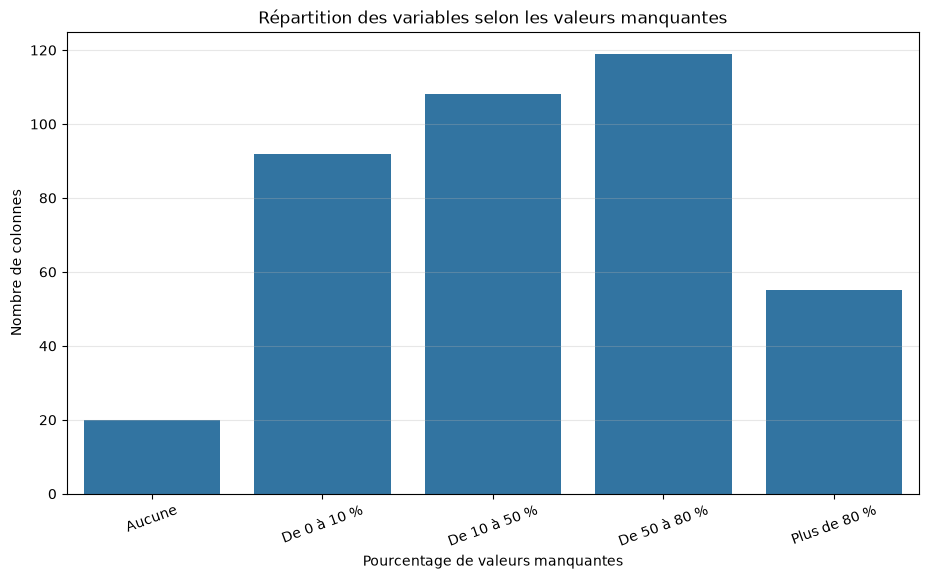

In [25]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=missing_distribution,
    x="Niveau de valeurs manquantes",
    y="Nombre de colonnes"
)

plt.title("Répartition des variables selon les valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [26]:
columns_to_examine = missing_full[
    missing_full["Pourcentage"] > 80
]

print(
    "Nombre de colonnes ayant plus de 80 % "
    "de valeurs manquantes :",
    len(columns_to_examine)
)

display(columns_to_examine)

Nombre de colonnes ayant plus de 80 % de valeurs manquantes : 55


,Valeurs_manquantes,Pourcentage
dist2,552913,93.628374
D7,551623,93.409930
D13,528588,89.509263
D14,528353,89.469469
D12,525823,89.041047
D6,517353,87.606767
D9,515614,87.312290
D8,515614,87.312290
V153,508595,86.123717
V149,508595,86.123717


In [27]:
IDENTITY_FILE = os.path.join(DATA_PATH, "train_identity.csv")

# Charger le fichier Identity
df_identity = pd.read_csv(IDENTITY_FILE)

# Afficher les premières lignes
display(df_identity.head())

# Afficher les dimensions du fichier
print("Nombre de lignes :", df_identity.shape[0])
print("Nombre de colonnes :", df_identity.shape[1])

# Vérifier les colonnes disponibles
print("\nListe des colonnes :")
print(df_identity.columns.tolist())

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


Nombre de lignes : 144233
Nombre de colonnes : 41

Liste des colonnes :
['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [28]:
identity_missing = pd.DataFrame({
    "Valeurs_manquantes": df_identity.isnull().sum(),
    "Pourcentage": (
        df_identity.isnull().sum() / len(df_identity)
    ) * 100
})

identity_missing = identity_missing.sort_values(
    by="Pourcentage",
    ascending=False
)

display(identity_missing.head(20).round(2))

,Valeurs_manquantes,Pourcentage
id_24,139486,96.71
id_25,139101,96.44
id_07,139078,96.43
id_08,139078,96.43
id_21,139074,96.42
id_26,139070,96.42
id_23,139064,96.42
id_27,139064,96.42
id_22,139064,96.42
id_18,99120,68.72


In [29]:
# Charger uniquement les colonnes nécessaires du fichier principal
df_transaction_identity = pd.read_csv(
    TRANSACTION_FILE,
    usecols=["TransactionID", "isFraud"],
    dtype={
        "TransactionID": "int32",
        "isFraud": "int8"
    }
)

# Identifier les TransactionID présents dans Identity
identity_ids = df_identity["TransactionID"]

# Ajouter une colonne indiquant la présence des informations Identity
df_transaction_identity["Identity_Disponible"] = (
    df_transaction_identity["TransactionID"].isin(identity_ids)
)

display(df_transaction_identity.head())

print(
    "Transactions avec Identity :",
    df_transaction_identity["Identity_Disponible"].sum()
)

print(
    "Transactions sans Identity :",
    (~df_transaction_identity["Identity_Disponible"]).sum()
)

,TransactionID,isFraud,Identity_Disponible
0,2987000,0,False
1,2987001,0,False
2,2987002,0,False
3,2987003,0,False
4,2987004,0,True


Transactions avec Identity : 144233
Transactions sans Identity : 446307


In [32]:
identity_fraud_stats = df_transaction_identity.groupby(
    "Identity_Disponible"
).agg(
    Total_Transactions=("isFraud", "count"),
    Total_Fraudes=("isFraud", "sum")
)

identity_fraud_stats["Taux_Fraude"] = (
    identity_fraud_stats["Total_Fraudes"]
    / identity_fraud_stats["Total_Transactions"]
) * 100

# Donner les bonnes étiquettes aux résultats
identity_fraud_stats = identity_fraud_stats.rename(
    index={
        True: "Identity disponible",
        False: "Identity indisponible"
    }
)

display(identity_fraud_stats.round(2))

,Total_Transactions,Total_Fraudes,Taux_Fraude
Identity_Disponible,,,
Identity indisponible,446307,9345,2.09
Identity disponible,144233,11318,7.85


In [34]:
# Charger le fichier principal
df_transaction = pd.read_csv(
    TRANSACTION_FILE,
    dtype={"TransactionID": "int32"}
)

# Fusionner avec le fichier Identity
df_merged = df_transaction.merge(
    df_identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

# Vérifier le résultat
print("Dimensions avant fusion :", df_transaction.shape)
print("Dimensions après fusion :", df_merged.shape)

print(
    "Transactions avec Identity :",
    df_merged["DeviceType"].notna().sum()
)

display(df_merged.head())

Dimensions avant fusion : (590540, 394)
Dimensions après fusion : (590540, 434)
Transactions avec Identity : 140810


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [35]:
# Compter les transactions présentes dans les deux fichiers
nb_correspondances = df_merged["TransactionID"].isin(
    df_identity["TransactionID"]
).sum()

# Compter les lignes ayant un DeviceType renseigné
nb_device_type = df_merged["DeviceType"].notna().sum()

print("Correspondances avec Identity :", nb_correspondances)
print("DeviceType renseigné :", nb_device_type)

print(
    "Correspondances sans DeviceType :",
    nb_correspondances - nb_device_type
)

Correspondances avec Identity : 144233
DeviceType renseigné : 140810
Correspondances sans DeviceType : 3423


In [36]:
# Définir le dossier de sauvegarde
PROCESSED_PATH = os.path.join(
    os.path.dirname(DATA_PATH),
    "processed"
)

# Créer le dossier s'il n'existe pas
os.makedirs(PROCESSED_PATH, exist_ok=True)

# Définir le chemin du fichier
MERGED_FILE = os.path.join(
    PROCESSED_PATH,
    "transactions_merged.parquet"
)

# Sauvegarder le dataset fusionné
df_merged.to_parquet(
    MERGED_FILE,
    index=False,
    compression="snappy"
)

print("Dataset sauvegardé avec succès !")
print("Chemin :", MERGED_FILE)

print(
    "Taille du fichier (Mo) :",
    round(os.path.getsize(MERGED_FILE) / (1024**2), 2)
)

Dataset sauvegardé avec succès !
Chemin : data\processed\transactions_merged.parquet
Taille du fichier (Mo) : 81.09


In [37]:
# Recharger le fichier Parquet
df_check = pd.read_parquet(MERGED_FILE)

print("Dimensions du fichier sauvegardé :", df_check.shape)

# Vérifier que le nombre de lignes est correct
assert df_check.shape[0] == 590540

# Vérifier que les informations Identity existent
assert "DeviceType" in df_check.columns
assert "DeviceInfo" in df_check.columns

print("Toutes les vérifications sont réussies !")

Dimensions du fichier sauvegardé : (590540, 434)
Toutes les vérifications sont réussies !


In [38]:
L'analyse exploratoire nous a déjà appris plusieurs choses :
- Le taux global de fraude est de 3,499 %.
- Le dataset contient 182 jours de transactions.
- Le taux de fraude varie selon ProductCD et card4.
- Certaines variables ont énormément de valeurs manquantes.
- Les informations Identity sont disponibles pour environ 24,42 % des transactions.
- La présence des informations Identity est associée à un taux de fraude plus élevé dans notre échantillon. Cette association ne signifie pas une relation de cause à effet.

SyntaxError: unterminated string literal (detected at line 1) (709306897.py, line 1)

In [39]:
# Charger le dataset fusionné
df = pd.read_parquet(MERGED_FILE)

# Afficher les dimensions
print("Nombre de transactions :", df.shape[0])
print("Nombre de variables :", df.shape[1])

# Afficher les premières lignes
display(df.head())

Nombre de transactions : 590540
Nombre de variables : 434


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [40]:
# Variables essentielles pour notre projet
essential_columns = [
    "TransactionID",
    "TransactionDT",
    "TransactionAmt",
    "isFraud",
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "ProductCD",
    "DeviceType",
    "DeviceInfo"
]

# Vérifier leur présence
for col in essential_columns:
    if col in df.columns:
        print("Disponible :", col)
    else:
        print("Absente :", col)

Disponible : TransactionID
Disponible : TransactionDT
Disponible : TransactionAmt
Disponible : isFraud
Disponible : card1
Disponible : card2
Disponible : card3
Disponible : card4
Disponible : card5
Disponible : ProductCD
Disponible : DeviceType
Disponible : DeviceInfo


In [41]:
# Créer le jour relatif de chaque transaction
df["TransactionDay"] = df["TransactionDT"] // 86400

# Afficher quelques exemples
display(
    df[["TransactionDT", "TransactionDay"]].head(10)
)

# Vérifier les jours minimum et maximum
print("Premier jour :", df["TransactionDay"].min())
print("Dernier jour :", df["TransactionDay"].max())
print("Nombre de jours :", df["TransactionDay"].nunique())

,TransactionDT,TransactionDay
0,86400,1
1,86401,1
2,86469,1
3,86499,1
4,86506,1
5,86510,1
6,86522,1
7,86529,1
8,86535,1
9,86536,1


Premier jour : 1
Dernier jour : 182
Nombre de jours : 182


In [42]:
# Calculer les secondes dans le cycle de 24 heures
df["TransactionSecondsInDay"] = df["TransactionDT"] % 86400

# Afficher les résultats
display(
    df[
        [
            "TransactionDT",
            "TransactionDay",
            "TransactionSecondsInDay"
        ]
    ].head(10)
)

,TransactionDT,TransactionDay,TransactionSecondsInDay
0,86400,1,0
1,86401,1,1
2,86469,1,69
3,86499,1,99
4,86506,1,106
5,86510,1,110
6,86522,1,122
7,86529,1,129
8,86535,1,135
9,86536,1,136


In [43]:
# Encodage cyclique du temps
df["Time_sin"] = np.sin(
    2 * np.pi * df["TransactionSecondsInDay"] / 86400
)

df["Time_cos"] = np.cos(
    2 * np.pi * df["TransactionSecondsInDay"] / 86400
)

# Afficher les nouvelles variables
display(
    df[
        [
            "TransactionDT",
            "TransactionSecondsInDay",
            "Time_sin",
            "Time_cos"
        ]
    ].head(10)
)

,TransactionDT,TransactionSecondsInDay,Time_sin,Time_cos
0,86400,0,0.000000,1.000000
1,86401,1,0.000073,1.000000
2,86469,69,0.005018,0.999987
3,86499,99,0.007199,0.999974
4,86506,106,0.007708,0.999970
5,86510,110,0.007999,0.999968
6,86522,122,0.008872,0.999961
7,86529,129,0.009381,0.999956
8,86535,135,0.009817,0.999952
9,86536,136,0.009890,0.999951


In [44]:
# Vérifier les nouvelles variables temporelles
temporal_columns = [
    "TransactionDay",
    "TransactionSecondsInDay",
    "Time_sin",
    "Time_cos"
]

display(df[temporal_columns].describe())

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df[temporal_columns].isnull().sum())

,TransactionDay,TransactionSecondsInDay,Time_sin,Time_cos
count,590540.000000,590540.00000,590540.000000,590540.000000
mean,84.729199,51708.54248,-0.340268,0.264983
std,53.437277,27427.81945,0.621251,0.654255
min,1.000000,0.00000,-1.000000,-1.000000
25%,35.000000,24428.25000,-0.890808,-0.289171
50%,84.000000,60624.00000,-0.545188,0.449644
75%,130.000000,73472.00000,0.112986,0.873241
max,182.000000,86399.00000,1.000000,1.000000



Valeurs manquantes :
TransactionDay             0
TransactionSecondsInDay    0
Time_sin                   0
Time_cos                   0
dtype: int64


In [45]:
# Colonnes relatives aux cartes
card_columns = [
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6"
]

# Afficher quelques exemples
display(df[card_columns].head(10))

# Examiner les valeurs manquantes
print("Valeurs manquantes par variable :")
print(df[card_columns].isnull().sum())

# Examiner le nombre de valeurs distinctes
print("\nNombre de valeurs distinctes :")
print(df[card_columns].nunique())

,card1,card2,card3,card4,card5,card6
0,13926,NaN,150.0,discover,142.0,credit
1,2755,404.0,150.0,mastercard,102.0,credit
2,4663,490.0,150.0,visa,166.0,debit
3,18132,567.0,150.0,mastercard,117.0,debit
4,4497,514.0,150.0,mastercard,102.0,credit
5,5937,555.0,150.0,visa,226.0,debit
6,12308,360.0,150.0,visa,166.0,debit
7,12695,490.0,150.0,visa,226.0,debit
8,2803,100.0,150.0,visa,226.0,debit
9,17399,111.0,150.0,mastercard,224.0,debit


Valeurs manquantes par variable :
card1       0
card2    8933
card3    1565
card4    1577
card5    4259
card6    1571
dtype: int64

Nombre de valeurs distinctes :
card1    13553
card2      500
card3      114
card4        4
card5      119
card6        4
dtype: int64


In [46]:
# Variables utilisées pour identifier un groupe de transactions
card_columns = [
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6"
]

# Construire un identifiant de groupe à partir des six variables
df["CardGroup"] = df.groupby(
    card_columns,
    dropna=False,
    sort=False
).ngroup()

# Afficher quelques exemples
display(
    df[
        card_columns + ["CardGroup"]
    ].head(15)
)

print(
    "Nombre de groupes comportementaux :",
    df["CardGroup"].nunique()
)

,card1,card2,card3,card4,card5,card6,CardGroup
0,13926,NaN,150.0,discover,142.0,credit,0
1,2755,404.0,150.0,mastercard,102.0,credit,1
2,4663,490.0,150.0,visa,166.0,debit,2
3,18132,567.0,150.0,mastercard,117.0,debit,3
4,4497,514.0,150.0,mastercard,102.0,credit,4
5,5937,555.0,150.0,visa,226.0,debit,5
6,12308,360.0,150.0,visa,166.0,debit,6
7,12695,490.0,150.0,visa,226.0,debit,7
8,2803,100.0,150.0,visa,226.0,debit,8
9,17399,111.0,150.0,mastercard,224.0,debit,9


Nombre de groupes comportementaux : 14893


In [47]:
# Calculer le nombre de transactions dans chaque groupe
group_sizes = df["CardGroup"].value_counts()

print("Nombre total de groupes :", len(group_sizes))

print(
    "Nombre de groupes avec une seule transaction :",
    (group_sizes == 1).sum()
)

print(
    "Nombre de groupes avec plusieurs transactions :",
    (group_sizes > 1).sum()
)

print(
    "Taille maximale d'un groupe :",
    group_sizes.max()
)

print("\nStatistiques sur la taille des groupes :")
display(group_sizes.describe())

Nombre total de groupes : 14893
Nombre de groupes avec une seule transaction : 4103
Nombre de groupes avec plusieurs transactions : 10790
Taille maximale d'un groupe : 14112

Statistiques sur la taille des groupes :


count    14893.000000
mean        39.652186
std        297.620053
min          1.000000
25%          1.000000
50%          4.000000
75%         12.000000
max      14112.000000
Name: count, dtype: float64

In [48]:
# Afficher les 10 groupes contenant le plus de transactions
top_groups = df["CardGroup"].value_counts().head(10)

print("Les 10 groupes les plus grands :")
display(top_groups)

# Récupérer l'identifiant du plus grand groupe
largest_group_id = top_groups.index[0]

# Afficher les informations de ce groupe
largest_group = df[
    df["CardGroup"] == largest_group_id
]

print("\nIdentifiant du plus grand groupe :", largest_group_id)
print("Nombre de transactions :", len(largest_group))

# Examiner les six variables utilisées pour créer le groupe
display(
    largest_group[
        card_columns
    ].drop_duplicates()
)

Les 10 groupes les plus grands :


CardGroup
88     14112
47     10332
60     10312
742     8844
70      7918
7       7079
127     6766
45      6760
8       6126
299     6047
Name: count, dtype: int64


Identifiant du plus grand groupe : 88
Nombre de transactions : 14112


,card1,card2,card3,card4,card5,card6
107,9500,321.0,150.0,visa,226.0,debit


In [49]:
# Vérifier si les transactions sont déjà dans l'ordre chronologique
is_chronological = df["TransactionDT"].is_monotonic_increasing

print("Données déjà triées chronologiquement :", is_chronological)

# Vérifier les valeurs de TransactionDT
print("TransactionDT minimum :", df["TransactionDT"].min())
print("TransactionDT maximum :", df["TransactionDT"].max())

# Vérifier les éventuels doublons de TransactionID
print(
    "Nombre de TransactionID dupliqués :",
    df["TransactionID"].duplicated().sum()
)

Données déjà triées chronologiquement : True
TransactionDT minimum : 86400
TransactionDT maximum : 15811131
Nombre de TransactionID dupliqués : 0


In [3]:
import os

print("Dossier de travail actuel :")
print(os.getcwd())

print("\nContenu du dossier actuel :")
print(os.listdir())

print("\nLe fichier Parquet existe-t-il ?")

chemins = [
    "data/processed/transactions_merged.parquet",
    "../data/processed/transactions_merged.parquet"
]

for chemin in chemins:
    print(chemin, ":", os.path.exists(chemin))

Dossier de travail actuel :
C:\Users\DELL\Desktop\Azza_Khechine\FraudDetectionXAI

Contenu du dossier actuel :
['.ipynb_checkpoints', '.venv', '01_Analyse_Exploratoire_IEEE_CIS.ipynb.ipynb', 'api', 'data', 'models', 'notebooks', 'outputs', 'pages', 'src', 'Untitled.ipynb']

Le fichier Parquet existe-t-il ?
data/processed/transactions_merged.parquet : True
../data/processed/transactions_merged.parquet : False


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

MERGED_FILE = os.path.join(
    "data",
    "processed",
    "transactions_merged.parquet"
)

df = pd.read_parquet(MERGED_FILE)

print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)

Dataset chargé avec succès !
Dimensions : (590540, 434)


In [5]:
print("TransactionDay :", "TransactionDay" in df.columns)
print("TransactionSecondsInDay :", "TransactionSecondsInDay" in df.columns)
print("Time_sin :", "Time_sin" in df.columns)
print("Time_cos :", "Time_cos" in df.columns)
print("CardGroup :", "CardGroup" in df.columns)

TransactionDay : False
TransactionSecondsInDay : False
Time_sin : False
Time_cos : False
CardGroup : False


In [6]:
# 1. Créer le numéro du jour relatif
df["TransactionDay"] = df["TransactionDT"] // 86400

# 2. Extraire les secondes dans le cycle de 24 heures
df["TransactionSecondsInDay"] = df["TransactionDT"] % 86400

# 3. Encoder le temps de manière cyclique
df["Time_sin"] = np.sin(
    2 * np.pi * df["TransactionSecondsInDay"] / 86400
)

df["Time_cos"] = np.cos(
    2 * np.pi * df["TransactionSecondsInDay"] / 86400
)

print("Variables temporelles recréées !")
print(df[[
    "TransactionDT",
    "TransactionDay",
    "TransactionSecondsInDay",
    "Time_sin",
    "Time_cos"
]].head())

Variables temporelles recréées !
   TransactionDT  TransactionDay  TransactionSecondsInDay  Time_sin  Time_cos
0          86400               1                        0  0.000000  1.000000
1          86401               1                        1  0.000073  1.000000
2          86469               1                       69  0.005018  0.999987
3          86499               1                       99  0.007199  0.999974
4          86506               1                      106  0.007708  0.999970


In [7]:
card_columns = [
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6"
]

df["CardGroup"] = df.groupby(
    card_columns,
    dropna=False,
    sort=False
).ngroup()

print("CardGroup recréé !")
print("Nombre de groupes :", df["CardGroup"].nunique())

CardGroup recréé !
Nombre de groupes : 14893


In [8]:
variables = [
    "TransactionDay",
    "TransactionSecondsInDay",
    "Time_sin",
    "Time_cos",
    "CardGroup"
]

for variable in variables:
    print(variable, ":", variable in df.columns)

TransactionDay : True
TransactionSecondsInDay : True
Time_sin : True
Time_cos : True
CardGroup : True


In [9]:
print(
    "Transactions classées chronologiquement :",
    df["TransactionDT"].is_monotonic_increasing
)

print(
    "Nombre de TransactionID dupliqués :",
    df["TransactionID"].duplicated().sum()
)

Transactions classées chronologiquement : True
Nombre de TransactionID dupliqués : 0


In [10]:
# Nombre de transactions précédentes du même groupe
df["Previous_Transaction_Count"] = (
    df.groupby("CardGroup").cumcount()
)

# Montant de la transaction précédente
df["Previous_Transaction_Amount"] = (
    df.groupby("CardGroup")["TransactionAmt"].shift(1)
)

# Somme des montants des transactions précédentes
previous_amount_sum = (
    df.groupby("CardGroup")["TransactionAmt"].cumsum()
    - df["TransactionAmt"]
)

# Montant moyen historique, sans utiliser la transaction actuelle
df["Historical_Average_Amount"] = (
    previous_amount_sum
    / df["Previous_Transaction_Count"].replace(0, np.nan)
)

# Temps écoulé depuis la transaction précédente (en secondes)
previous_transaction_time = (
    df.groupby("CardGroup")["TransactionDT"].shift(1)
)

df["Time_Since_Last_Transaction"] = (
    df["TransactionDT"] - previous_transaction_time
)

print("Variables comportementales créées !")

Variables comportementales créées !


In [11]:
behavior_columns = [
    "CardGroup",
    "TransactionDT",
    "TransactionAmt",
    "Previous_Transaction_Count",
    "Previous_Transaction_Amount",
    "Historical_Average_Amount",
    "Time_Since_Last_Transaction",
    "isFraud"
]

df[behavior_columns].head(15)

,CardGroup,TransactionDT,TransactionAmt,Previous_Transaction_Count,Previous_Transaction_Amount,Historical_Average_Amount,Time_Since_Last_Transaction,isFraud
0,0,86400,68.500,0,NaN,NaN,NaN,0
1,1,86401,29.000,0,NaN,NaN,NaN,0
2,2,86469,59.000,0,NaN,NaN,NaN,0
3,3,86499,50.000,0,NaN,NaN,NaN,0
4,4,86506,50.000,0,NaN,NaN,NaN,0
5,5,86510,49.000,0,NaN,NaN,NaN,0
6,6,86522,159.000,0,NaN,NaN,NaN,0
7,7,86529,422.500,0,NaN,NaN,NaN,0
8,8,86535,15.000,0,NaN,NaN,NaN,0
9,9,86536,117.000,0,NaN,NaN,NaN,0


In [12]:
df[[
    "Previous_Transaction_Count",
    "Previous_Transaction_Amount",
    "Historical_Average_Amount",
    "Time_Since_Last_Transaction"
]].describe()

,Previous_Transaction_Count,Previous_Transaction_Amount,Historical_Average_Amount,Time_Since_Last_Transaction
count,590540.000000,575647.000000,575647.000000,5.756470e+05
mean,1136.184436,134.651726,129.034601,1.729783e+05
std,1978.516444,238.807422,81.314809,7.164971e+05
min,0.000000,0.251000,0.615000,0.000000e+00
25%,39.000000,42.950000,91.746971,9.900000e+02
50%,283.000000,68.500000,115.566790,6.000000e+03
75%,1282.000000,124.063000,147.765007,5.905250e+04
max,14111.000000,31937.391000,4517.710000,1.559967e+07


In [13]:
# Calculer le nombre de transactions par groupe
group_sizes = df["CardGroup"].value_counts()

print("Nombre total de groupes :", len(group_sizes))

print("\nStatistiques des tailles des groupes :")
print(group_sizes.describe())

print("\nNombre de groupes ayant plus de :")

for seuil in [100, 500, 1000, 5000]:
    nombre = (group_sizes > seuil).sum()
    print(f"{seuil} transactions : {nombre} groupes")

print("\nPourcentage des transactions appartenant aux groupes de plus de 1000 transactions :")

nombre_transactions = df["CardGroup"].map(group_sizes)

pourcentage = (nombre_transactions > 1000).mean() * 100

print(f"{pourcentage:.2f} %")


Nombre total de groupes : 14893

Statistiques des tailles des groupes :
count    14893.000000
mean        39.652186
std        297.620053
min          1.000000
25%          1.000000
50%          4.000000
75%         12.000000
max      14112.000000
Name: count, dtype: float64

Nombre de groupes ayant plus de :
100 transactions : 717 groupes
500 transactions : 197 groupes
1000 transactions : 99 groupes
5000 transactions : 13 groupes

Pourcentage des transactions appartenant aux groupes de plus de 1000 transactions :
45.87 %


In [14]:
# Nombre de transactions pour chaque valeur de card1
card1_sizes = df["card1"].value_counts(dropna=False)

print("Nombre de valeurs distinctes de card1 :",
      df["card1"].nunique())

print("\nStatistiques des fréquences :")
print(card1_sizes.describe())

print("\nLes 10 valeurs de card1 les plus fréquentes :")
print(card1_sizes.head(10))

Nombre de valeurs distinctes de card1 : 13553

Statistiques des fréquences :
count    13553.000000
mean        43.572641
std        329.084462
min          1.000000
25%          1.000000
50%          4.000000
75%         14.000000
max      14932.000000
Name: count, dtype: float64

Les 10 valeurs de card1 les plus fréquentes :
card1
7919     14932
9500     14162
15885    10361
17188    10344
15066     7945
12695     7091
12544     6773
6019      6771
2803      6141
7585      5334
Name: count, dtype: int64


In [15]:
# Examiner les caractéristiques du plus grand CardGroup
largest_group_id = group_sizes.idxmax()

print("Identifiant du plus grand groupe :",
      largest_group_id)

print("\nCaractéristiques de ce groupe :")

print(
    df.loc[
        df["CardGroup"] == largest_group_id,
        ["card1", "card2", "card3", "card4", "card5", "card6"]
    ].drop_duplicates()
)

print("\nNombre de transactions :",
      group_sizes.max())

Identifiant du plus grand groupe : 88

Caractéristiques de ce groupe :
     card1  card2  card3 card4  card5  card6
107   9500  321.0  150.0  visa  226.0  debit

Nombre de transactions : 14112


In [16]:
# Récupérer les données sous forme de tableaux NumPy
transaction_times = df["TransactionDT"].to_numpy()
transaction_amounts = df["TransactionAmt"].to_numpy()

# Préparer les tableaux de résultats
n = len(df)

count_1h = np.zeros(n, dtype=np.int32)
count_24h = np.zeros(n, dtype=np.int32)
average_24h = np.full(n, np.nan, dtype=np.float64)

# Regrouper les positions des transactions par CardGroup
groups = df.groupby("CardGroup", sort=False).indices

# Parcourir chaque groupe
for positions in groups.values():

    # Garantir l'ordre chronologique
    positions = np.sort(positions)

    # Récupérer les temps et montants du groupe
    times = transaction_times[positions]
    amounts = transaction_amounts[positions]

    # Positions dans le groupe
    indices = np.arange(len(positions))

    # Déterminer le début des fenêtres temporelles
    left_1h = np.searchsorted(
        times, times - 3600, side="left"
    )

    left_24h = np.searchsorted(
        times, times - 86400, side="left"
    )

    # Nombre de transactions précédentes
    count_1h[positions] = indices - left_1h
    count_24h[positions] = indices - left_24h

    # Calculer les montants cumulés
    cumulative_amounts = np.concatenate(
        ([0.0], np.cumsum(amounts))
    )

    # Somme des montants précédents sur 24 heures
    sum_24h = (
        cumulative_amounts[indices]
        - cumulative_amounts[left_24h]
    )

    # Calculer la moyenne historique sur 24 heures
    valid = count_24h[positions] > 0

    average_24h[positions[valid]] = (
        sum_24h[valid] / count_24h[positions][valid]
    )

# Ajouter les nouvelles variables au dataset
df["Previous_Transactions_1h"] = count_1h
df["Previous_Transactions_24h"] = count_24h
df["Average_Amount_24h"] = average_24h

print("Les variables comportementales temporelles ont été créées !")

Les variables comportementales temporelles ont été créées !


In [17]:
new_columns = [
    "Previous_Transactions_1h",
    "Previous_Transactions_24h",
    "Average_Amount_24h"
]

print("Statistiques des nouvelles variables :")
display(df[new_columns].describe())

print("\nExemples de transactions :")

display(
    df[
        [
            "CardGroup",
            "TransactionDT",
            "TransactionAmt",
            "Previous_Transactions_1h",
            "Previous_Transactions_24h",
            "Average_Amount_24h"
        ]
    ].head(15)
)

Statistiques des nouvelles variables :


,Previous_Transactions_1h,Previous_Transactions_24h,Average_Amount_24h
count,590540.000000,590540.000000,461248.000000
mean,1.437669,18.308072,134.686501
std,5.469185,43.836775,148.607939
min,0.000000,0.000000,1.251000
25%,0.000000,1.000000,64.767786
50%,0.000000,5.000000,102.726112
75%,1.000000,19.000000,151.987478
max,191.000000,880.000000,5279.950000



Exemples de transactions :


,CardGroup,TransactionDT,TransactionAmt,Previous_Transactions_1h,Previous_Transactions_24h,Average_Amount_24h
0,0,86400,68.500,0,0,NaN
1,1,86401,29.000,0,0,NaN
2,2,86469,59.000,0,0,NaN
3,3,86499,50.000,0,0,NaN
4,4,86506,50.000,0,0,NaN
5,5,86510,49.000,0,0,NaN
6,6,86522,159.000,0,0,NaN
7,7,86529,422.500,0,0,NaN
8,8,86535,15.000,0,0,NaN
9,9,86536,117.000,0,0,NaN


In [18]:
data/processed/transactions_features.parquet

NameError: name 'data' is not defined

In [19]:
# Définir le chemin de sauvegarde
FEATURES_FILE = os.path.join(
    "data",
    "processed",
    "transactions_features.parquet"
)

# Sauvegarder le dataset enrichi
df.to_parquet(FEATURES_FILE, index=False)

print("Dataset sauvegardé avec succès !")
print("Chemin :", FEATURES_FILE)
print("Dimensions :", df.shape)

Dataset sauvegardé avec succès !
Chemin : data\processed\transactions_features.parquet
Dimensions : (590540, 446)


In [20]:
print(
    "Fichier enregistré :",
    os.path.exists(FEATURES_FILE)
)

Fichier enregistré : True


In [21]:
# Vérifier l'ordre chronologique
assert df["TransactionDT"].is_monotonic_increasing

# Nombre total de transactions
n = len(df)

# Calculer les limites
train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Séparer chronologiquement
train_df = df.iloc[:train_end].copy()

val_df = df.iloc[train_end:val_end].copy()

test_df = df.iloc[val_end:].copy()

# Afficher les dimensions
print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

Train : (354324, 446)
Validation : (118108, 446)
Test : (118108, 446)


In [22]:
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    fraud_count = subset["isFraud"].sum()
    fraud_rate = subset["isFraud"].mean() * 100

    print(f"\n{name}")
    print("Nombre de transactions :", len(subset))
    print("Nombre de fraudes :", int(fraud_count))
    print("Taux de fraude :", round(fraud_rate, 3), "%")
    print(
        "Période TransactionDT :",
        subset["TransactionDT"].min(),
        "à",
        subset["TransactionDT"].max()
    )


Train
Nombre de transactions : 354324
Nombre de fraudes : 11988
Taux de fraude : 3.383 %
Période TransactionDT : 86400 à 8745772

Validation
Nombre de transactions : 118108
Nombre de fraudes : 4611
Taux de fraude : 3.904 %
Période TransactionDT : 8745798 à 12192842

Test
Nombre de transactions : 118108
Nombre de fraudes : 4064
Taux de fraude : 3.441 %
Période TransactionDT : 12192900 à 15811131


In [23]:
import os

# Créer le dossier de sauvegarde s'il n'existe pas
os.makedirs("data/processed", exist_ok=True)

# Définir les chemins
TRAIN_FILE = "data/processed/train.parquet"
VAL_FILE = "data/processed/validation.parquet"
TEST_FILE = "data/processed/test.parquet"

# Sauvegarder les trois ensembles
train_df.to_parquet(TRAIN_FILE, index=False)
val_df.to_parquet(VAL_FILE, index=False)
test_df.to_parquet(TEST_FILE, index=False)

print("Les trois ensembles ont été sauvegardés !")

print("Train :", os.path.exists(TRAIN_FILE))
print("Validation :", os.path.exists(VAL_FILE))
print("Test :", os.path.exists(TEST_FILE))

Les trois ensembles ont été sauvegardés !
Train : True
Validation : True
Test : True


In [24]:
# Identifier la variable cible
TARGET = "isFraud"

# Colonnes à exclure des variables explicatives
excluded_columns = [
    "isFraud",
    "TransactionID",
    "TransactionDT",
    "CardGroup"
]

# Construire la liste des variables explicatives
feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

# Séparer les variables et la cible
X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].copy()

print("Nombre de variables explicatives :", len(feature_columns))

print("\nDimensions :")
print("X_train :", X_train.shape)
print("X_val :", X_val.shape)
print("X_test :", X_test.shape)

print("\nRépartition des types de variables :")
print(X_train.dtypes.value_counts())

Nombre de variables explicatives : 442

Dimensions :
X_train : (354324, 442)
X_val : (118108, 442)
X_test : (118108, 442)

Répartition des types de variables :
float64    405
str         31
int64        4
int32        2
Name: count, dtype: int64


In [25]:
# Séparer les variables numériques et catégorielles
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Nombre de variables numériques :", len(numeric_features))
print("Nombre de variables catégorielles :", len(categorical_features))

# Calculer le pourcentage de valeurs manquantes
missing_percent = (
    X_train.isnull().mean() * 100
).sort_values(ascending=False)

print("\nLes 20 variables avec le plus de valeurs manquantes :")
display(missing_percent.head(20).to_frame("Missing (%)"))

# Identifier les variables très incomplètes
high_missing = missing_percent[missing_percent > 95]

print("\nVariables avec plus de 95 % de valeurs manquantes :")
print(high_missing)

Nombre de variables numériques : 411
Nombre de variables catégorielles : 31

Les 20 variables avec le plus de valeurs manquantes :


,Missing (%)
id_24,99.076551
id_25,99.005712
id_08,99.002043
id_07,99.002043
id_26,99.001479
id_21,99.000914
id_27,98.999786
id_23,98.999786
id_22,98.999786
D7,93.773778



Variables avec plus de 95 % de valeurs manquantes :
id_24    99.076551
id_25    99.005712
id_08    99.002043
id_07    99.002043
id_26    99.001479
id_21    99.000914
id_27    98.999786
id_23    98.999786
id_22    98.999786
dtype: float64


In [26]:
import sklearn
import xgboost

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("XGBoost :", xgboost.__version__)

ModuleNotFoundError: No module named 'sklearn'

In [27]:
import sys

print("Python utilisé par le notebook :")
print(sys.executable)

Python utilisé par le notebook :
C:\Users\DELL\Desktop\Azza_Khechine\FraudDetectionXAI\.venv\Scripts\python.exe


In [28]:
import sys

!{sys.executable} -m pip install -U scikit-learn xgboost

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
 

In [29]:
import pandas as pd
import numpy as np
import sklearn
import xgboost

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("XGBoost :", xgboost.__version__)

Pandas : 3.1.0
NumPy : 2.5.4
Scikit-learn : 1.9.1
XGBoost : 3.4.1


In [30]:
print("Dimensions des données :")
print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("\nNombre de fraudes :")
print("Train :", int(y_train.sum()))
print("Validation :", int(y_val.sum()))
print("Test :", int(y_test.sum()))

Dimensions des données :
X_train : (354324, 442)
X_val   : (118108, 442)
X_test  : (118108, 442)

Nombre de fraudes :
Train : 11988
Validation : 4611
Test : 4064


In [31]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identifier les variables numériques et catégorielles
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Variables numériques :", len(numeric_features))
print("Variables catégorielles :", len(categorical_features))

# Traitement des variables numériques
numeric_transformer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

# Traitement des variables catégorielles
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="MISSING"
    )),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        dtype=np.float32
    ))
])

# Combiner les deux traitements
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nPréprocesseur créé avec succès !")

Variables numériques : 411
Variables catégorielles : 31

Préprocesseur créé avec succès !


In [32]:
print("Transformation des données d'entraînement...")

X_train_processed = preprocessor.fit_transform(X_train)

print("Transformation des données de validation...")

X_val_processed = preprocessor.transform(X_val)

print("Transformation des données de test...")

X_test_processed = preprocessor.transform(X_test)

# Réduire la consommation de mémoire
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

print("\nTransformation terminée !")

print("Train :", X_train_processed.shape)
print("Validation :", X_val_processed.shape)
print("Test :", X_test_processed.shape)

print("\nValeurs manquantes restantes :")
print("Train :", np.isnan(X_train_processed).sum())
print("Validation :", np.isnan(X_val_processed).sum())
print("Test :", np.isnan(X_test_processed).sum())

Transformation des données d'entraînement...
Transformation des données de validation...
Transformation des données de test...

Transformation terminée !
Train : (354324, 442)
Validation : (118108, 442)
Test : (118108, 442)

Valeurs manquantes restantes :
Train : 0
Validation : 0
Test : 0


In [33]:
from xgboost import XGBClassifier
import numpy as np
import joblib
import os

# Calcul du déséquilibre entre les deux classes
nombre_normales = int((y_train == 0).sum())
nombre_fraudes = int((y_train == 1).sum())

scale_pos_weight = nombre_normales / nombre_fraudes

print("Transactions normales :", nombre_normales)
print("Transactions frauduleuses :", nombre_fraudes)
print("Poids de la classe fraude :", scale_pos_weight)

# Création du modèle
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    max_bin=256,
    reg_lambda=5,
    min_child_weight=5,
    n_jobs=-1,
    random_state=42
)

# Entraînement
print("\nDébut de l'entraînement...")

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=20
)

print("\nEntraînement terminé !")

Transactions normales : 342336
Transactions frauduleuses : 11988
Poids de la classe fraude : 28.556556556556558

Début de l'entraînement...
[0]	validation_0-aucpr:0.35949
[20]	validation_0-aucpr:0.46117
[40]	validation_0-aucpr:0.48102
[60]	validation_0-aucpr:0.50705
[80]	validation_0-aucpr:0.52175
[99]	validation_0-aucpr:0.53014

Entraînement terminé !


In [34]:
os.makedirs("models", exist_ok=True)

joblib.dump(xgb_model, "models/xgboost_model.pkl")
joblib.dump(preprocessor, "models/preprocessor.pkl")

print("Modèle sauvegardé : models/xgboost_model.pkl")
print("Préprocesseur sauvegardé : models/preprocessor.pkl")

Modèle sauvegardé : models/xgboost_model.pkl
Préprocesseur sauvegardé : models/preprocessor.pkl


In [35]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import numpy as np
import pandas as pd

# Probabilités prédites sur la validation
y_val_proba = xgb_model.predict_proba(X_val_processed)[:, 1]

# Prédictions avec un seuil provisoire de 0.5
y_val_pred = (y_val_proba >= 0.5).astype(int)

print("Prédictions calculées !")
print("Nombre de probabilités :", len(y_val_proba))
print("Probabilité minimale :", y_val_proba.min())
print("Probabilité maximale :", y_val_proba.max())

Prédictions calculées !
Nombre de probabilités : 118108
Probabilité minimale : 0.036173753
Probabilité maximale : 0.9934376


In [36]:
pr_auc = average_precision_score(y_val, y_val_proba)

roc_auc = roc_auc_score(y_val, y_val_proba)

print("PR-AUC :", round(pr_auc, 4))
print("ROC-AUC :", round(roc_auc, 4))

PR-AUC : 0.5302
ROC-AUC : 0.9023


In [37]:
# Nombre total de transactions dans la validation
n = len(y_val_proba)

# Trier les transactions de la plus suspecte à la moins suspecte
indices_tries = np.argsort(y_val_proba)[::-1]

# Convertir y_val en tableau NumPy
y_val_array = np.asarray(y_val)

# Différents budgets d'investigation
budgets = [0.5, 1, 2, 5]

resultats_k = []

for budget in budgets:

    # Nombre de transactions que les analystes peuvent examiner
    k = int(n * budget / 100)

    # Sélectionner les K transactions les plus suspectes
    top_k_indices = indices_tries[:k]

    # Nombre de fraudes parmi les K transactions
    fraudes_detectees = y_val_array[top_k_indices].sum()

    # Precision@K
    precision_k = fraudes_detectees / k

    # Recall@K
    recall_k = fraudes_detectees / y_val_array.sum()

    resultats_k.append({
        "Budget (%)": budget,
        "Transactions examinées": k,
        "Fraudes détectées": int(fraudes_detectees),
        "Precision@K": precision_k,
        "Recall@K": recall_k
    })

resultats_k_df = pd.DataFrame(resultats_k)

display(resultats_k_df)

,Budget (%),Transactions examinées,Fraudes détectées,Precision@K,Recall@K
0,0.5,590,525,0.889831,0.113858
1,1.0,1181,1048,0.887384,0.227283
2,2.0,2362,1743,0.737934,0.378009
3,5.0,5905,2596,0.439627,0.563002


In [38]:
f2 = fbeta_score(y_val, y_val_pred, beta=2)

mcc = matthews_corrcoef(y_val, y_val_pred)

precision = precision_score(y_val, y_val_pred, zero_division=0)

recall = recall_score(y_val, y_val_pred, zero_division=0)

print("Résultats avec le seuil 0.5")
print("--------------------------------")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F2-score  :", round(f2, 4))
print("MCC       :", round(mcc, 4))

Résultats avec le seuil 0.5
--------------------------------
Precision : 0.1992
Recall    : 0.7684
F2-score  : 0.489
MCC       : 0.3482


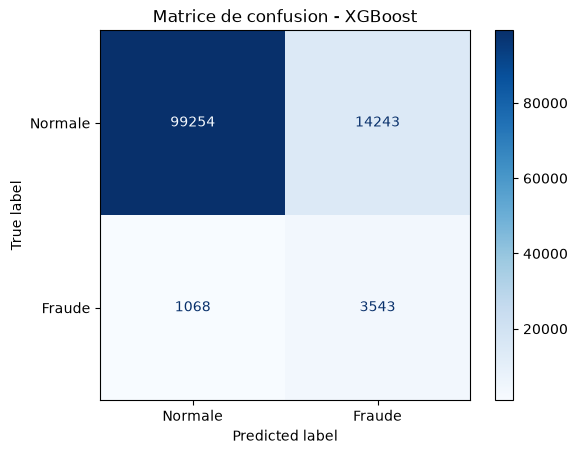

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normale", "Fraude"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion - XGBoost")
plt.show()

In [40]:
# Variables numériques représentatives pour la détection d'anomalies

candidates = [
    "TransactionAmt",
    "TransactionDay",
    "TransactionSecondsInDay",
    "Time_sin",
    "Time_cos",
    "Previous_Transaction_Count",
    "Previous_Transaction_Amount",
    "Historical_Average_Amount",
    "Time_Since_Last_Transaction",
    "Previous_Transactions_1h",
    "Previous_Transactions_24h",
    "Average_Amount_24h",
    "card1",
    "card2",
    "card3",
    "card5",
    "C1",
    "C2",
    "D1",
    "D2"
]

# Garder uniquement les variables disponibles dans X_train
anomaly_features = [
    col for col in candidates
    if col in X_train.columns
    and pd.api.types.is_numeric_dtype(X_train[col])
]

print("Variables sélectionnées :", len(anomaly_features))
print(anomaly_features)

Variables sélectionnées : 20
['TransactionAmt', 'TransactionDay', 'TransactionSecondsInDay', 'Time_sin', 'Time_cos', 'Previous_Transaction_Count', 'Previous_Transaction_Amount', 'Historical_Average_Amount', 'Time_Since_Last_Transaction', 'Previous_Transactions_1h', 'Previous_Transactions_24h', 'Average_Amount_24h', 'card1', 'card2', 'card3', 'card5', 'C1', 'C2', 'D1', 'D2']


In [41]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Générateur aléatoire reproductible
rng = np.random.default_rng(42)

# Échantillon d'entraînement
train_indices = rng.choice(
    len(X_train),
    size=10000,
    replace=False
)

# Échantillon de validation commun aux deux modèles
val_indices = rng.choice(
    len(X_val),
    size=20000,
    replace=False
)

# Extraire les variables sélectionnées
X_anomaly_train = X_train.iloc[
    train_indices
][anomaly_features]

X_anomaly_val = X_val.iloc[
    val_indices
][anomaly_features]

# Imputation des valeurs manquantes
anomaly_imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_anomaly_train_imp = anomaly_imputer.fit_transform(
    X_anomaly_train
)

X_anomaly_val_imp = anomaly_imputer.transform(
    X_anomaly_val
)

# Standardisation
anomaly_scaler = StandardScaler()

X_anomaly_train_scaled = anomaly_scaler.fit_transform(
    X_anomaly_train_imp
).astype(np.float32)

X_anomaly_val_scaled = anomaly_scaler.transform(
    X_anomaly_val_imp
).astype(np.float32)

# Étiquettes de validation, uniquement pour l'évaluation
y_anomaly_val = np.asarray(y_val)[val_indices]

print("Préparation terminée !")
print("Train :", X_anomaly_train_scaled.shape)
print("Validation :", X_anomaly_val_scaled.shape)
print("Fraudes dans la validation :", int(y_anomaly_val.sum()))

Préparation terminée !
Train : (10000, 20)
Validation : (20000, 20)
Fraudes dans la validation : 770


In [42]:
from sklearn.ensemble import IsolationForest
import time

isolation_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("Entraînement Isolation Forest...")
start = time.time()

isolation_model.fit(X_anomaly_train_scaled)

print("Entraînement terminé !")
print("Durée :", round(time.time() - start, 2), "secondes")

# Plus le score est élevé, plus la transaction est anormale
isolation_scores = -isolation_model.decision_function(
    X_anomaly_val_scaled
)

print("Scores calculés :", len(isolation_scores))

Entraînement Isolation Forest...
Entraînement terminé !
Durée : 0.21 secondes
Scores calculés : 20000


In [43]:
from sklearn.neighbors import LocalOutlierFactor
import time

lof_train_indices = rng.choice(
    len(X_anomaly_train_scaled),
    size=5000,
    replace=False
)

X_lof_train = X_anomaly_train_scaled[lof_train_indices]

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    contamination="auto",
    n_jobs=-1
)

print("Entraînement LOF...")
start = time.time()

lof_model.fit(X_lof_train)

print("Entraînement terminé !")
print("Durée :", round(time.time() - start, 2), "secondes")

# Plus le score est élevé, plus la transaction est suspecte
lof_scores = -lof_model.decision_function(
    X_anomaly_val_scaled
)

print("Scores calculés :", len(lof_scores))

Entraînement LOF...
Entraînement terminé !
Durée : 0.29 secondes
Scores calculés : 20000


In [44]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Scores XGBoost sur les mêmes transactions
xgb_scores_sample = y_val_proba[val_indices]

models_scores = {
    "XGBoost": xgb_scores_sample,
    "Isolation Forest": isolation_scores,
    "LOF": lof_scores
}

comparison = []

for model_name, scores in models_scores.items():

    pr = average_precision_score(
        y_anomaly_val,
        scores
    )

    roc = roc_auc_score(
        y_anomaly_val,
        scores
    )

    comparison.append({
        "Modèle": model_name,
        "PR-AUC": pr,
        "ROC-AUC": roc
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).reset_index(drop=True)
)

,Modèle,PR-AUC,ROC-AUC
0,XGBoost,0.539718,0.911865
1,Isolation Forest,0.054651,0.615905
2,LOF,0.052314,0.541365


In [45]:
import os
import joblib

os.makedirs("models", exist_ok=True)

# Sauvegarder les modèles
joblib.dump(isolation_model, "models/isolation_forest.pkl")
joblib.dump(lof_model, "models/lof_model.pkl")

# Sauvegarder les outils de préparation des données des modèles non supervisés
joblib.dump(anomaly_imputer, "models/anomaly_imputer.pkl")
joblib.dump(anomaly_scaler, "models/anomaly_scaler.pkl")

# Sauvegarder les noms des variables utilisées
joblib.dump(anomaly_features, "models/anomaly_features.pkl")

print("Tous les modèles ont été sauvegardés !")
print("\nFichiers disponibles :")

for fichier in os.listdir("models"):
    print("-", fichier)

Tous les modèles ont été sauvegardés !

Fichiers disponibles :
- anomaly_features.pkl
- anomaly_imputer.pkl
- anomaly_scaler.pkl
- isolation_forest.pkl
- lof_model.pkl
- preprocessor.pkl
- xgboost_model.pkl


In [46]:
# Récupérer les montants des transactions de validation
amounts_val = X_val["TransactionAmt"].to_numpy(dtype=float)

# Récupérer les vraies étiquettes
y_val_array = np.asarray(y_val)

# Coût hypothétique d'une investigation
investigation_cost = 5.0

print("Nombre de transactions :", len(y_val_array))
print("Nombre de fraudes :", int(y_val_array.sum()))
print("Coût par investigation :", investigation_cost)

Nombre de transactions : 118108
Nombre de fraudes : 4611
Coût par investigation : 5.0


In [47]:
# Différents seuils à tester
thresholds = np.arange(0.05, 0.96, 0.01)

results_threshold = []

for threshold in thresholds:

    # Prédictions selon le seuil
    predictions = (y_val_proba >= threshold).astype(int)

    # Fraudes non détectées
    false_negatives = (y_val_array == 1) & (predictions == 0)

    # Nombre d'alertes
    number_alerts = int(predictions.sum())

    # Pertes estimées
    missed_fraud_loss = amounts_val[false_negatives].sum()

    # Coût des investigations
    investigation_total = number_alerts * investigation_cost

    # Coût total
    total_cost = missed_fraud_loss + investigation_total

    results_threshold.append({
        "Threshold": threshold,
        "Alerts": number_alerts,
        "Missed_Frauds": int(false_negatives.sum()),
        "Missed_Loss": missed_fraud_loss,
        "Investigation_Cost": investigation_total,
        "Total_Cost": total_cost
    })

threshold_df = pd.DataFrame(results_threshold)

# Seuil qui minimise le coût
best_result = threshold_df.loc[
    threshold_df["Total_Cost"].idxmin()
]

display(threshold_df.sort_values("Total_Cost").head(10))

print("\nMeilleur seuil :", round(best_result["Threshold"], 2))
print("Nombre d'alertes :", int(best_result["Alerts"]))
print("Fraudes manquées :", int(best_result["Missed_Frauds"]))
print("Coût total estimé :", round(best_result["Total_Cost"], 2))

,Threshold,Alerts,Missed_Frauds,Missed_Loss,Investigation_Cost,Total_Cost
40,0.45,21971,890,146674.728,109855.0,256529.728
41,0.46,21082,932,152219.545,105410.0,257629.545
42,0.47,20200,960,157077.532,101000.0,258077.532
38,0.43,23838,841,139014.351,119190.0,258204.351
39,0.44,22895,872,143848.026,114475.0,258323.026
43,0.48,19324,995,162342.930,96620.0,258962.930
37,0.42,24785,820,136340.434,123925.0,260265.434
44,0.49,18538,1030,167786.877,92690.0,260476.877
36,0.41,25816,791,132649.257,129080.0,261729.257
35,0.40,26828,763,128821.571,134140.0,262961.571



Meilleur seuil : 0.45
Nombre d'alertes : 21971
Fraudes manquées : 890
Coût total estimé : 256529.73


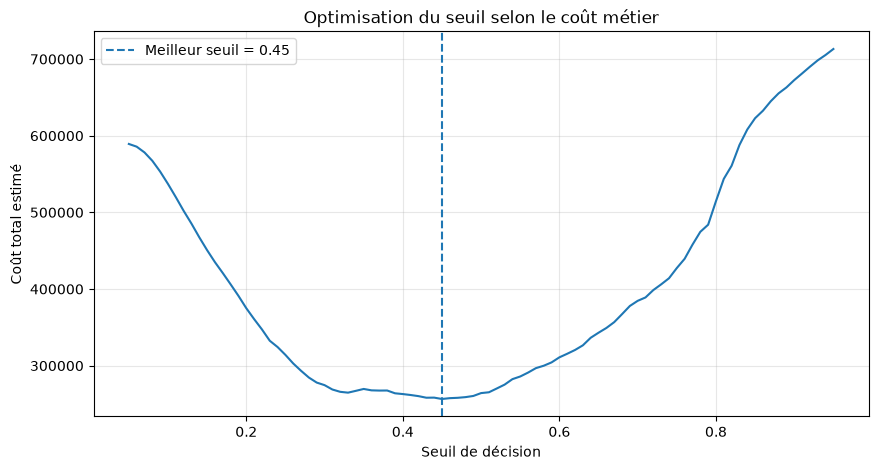

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total_Cost"]
)

plt.axvline(
    best_result["Threshold"],
    linestyle="--",
    label=f"Meilleur seuil = {best_result['Threshold']:.2f}"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Coût total estimé")
plt.title("Optimisation du seuil selon le coût métier")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [49]:
# Probabilités de fraude sur le jeu de test
y_test_proba = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Seuil choisi sur la validation
best_threshold = float(best_result["Threshold"])

# Prédictions finales
y_test_pred = (
    y_test_proba >= best_threshold
).astype(int)

print("Seuil retenu :", best_threshold)
print("Nombre de transactions test :", len(y_test))
print("Nombre d'alertes :", int(y_test_pred.sum()))

Seuil retenu : 0.45000000000000007
Nombre de transactions test : 118108
Nombre d'alertes : 23039


In [50]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score,
    matthews_corrcoef,
    confusion_matrix
)

test_pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_f2 = fbeta_score(
    y_test,
    y_test_pred,
    beta=2,
    zero_division=0
)

test_mcc = matthews_corrcoef(
    y_test,
    y_test_pred
)

print("===== ÉVALUATION FINALE SUR TEST =====")
print("PR-AUC   :", round(test_pr_auc, 4))
print("ROC-AUC  :", round(test_roc_auc, 4))
print("Precision:", round(test_precision, 4))
print("Recall   :", round(test_recall, 4))
print("F2-score :", round(test_f2, 4))
print("MCC      :", round(test_mcc, 4))

===== ÉVALUATION FINALE SUR TEST =====
PR-AUC   : 0.457
ROC-AUC  : 0.8808
Precision: 0.1363
Recall   : 0.7729
F2-score : 0.3997
MCC      : 0.2753


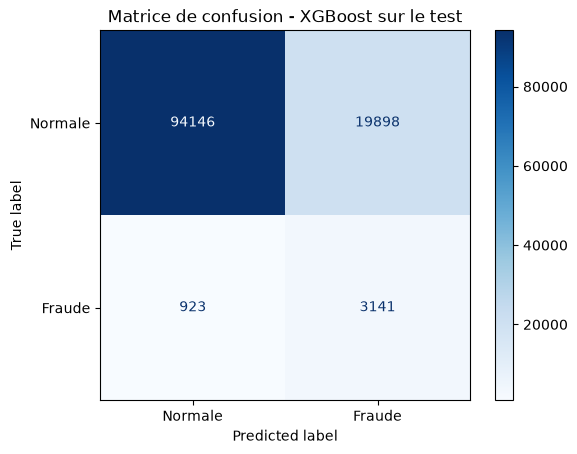

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_test = confusion_matrix(
    y_test,
    y_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Normale", "Fraude"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion - XGBoost sur le test")
plt.show()

In [52]:
amounts_test = X_test["TransactionAmt"].to_numpy(dtype=float)

y_test_array = np.asarray(y_test)

false_negatives_test = (
    (y_test_array == 1) & (y_test_pred == 0)
)

test_alerts = int(y_test_pred.sum())

test_missed_loss = amounts_test[
    false_negatives_test
].sum()

test_investigation_cost = (
    test_alerts * investigation_cost
)

test_total_cost = (
    test_missed_loss + test_investigation_cost
)

print("===== COÛT MÉTIER SUR TEST =====")
print("Seuil :", best_threshold)
print("Alertes :", test_alerts)
print("Fraudes manquées :", int(false_negatives_test.sum()))
print("Pertes estimées :", round(test_missed_loss, 2))
print("Coût des investigations :", round(test_investigation_cost, 2))
print("Coût total :", round(test_total_cost, 2))

===== COÛT MÉTIER SUR TEST =====
Seuil : 0.45000000000000007
Alertes : 23039
Fraudes manquées : 923
Pertes estimées : 142804.51
Coût des investigations : 115195.0
Coût total : 257999.51


In [53]:
joblib.dump(
    {
        "threshold": best_threshold,
        "investigation_cost": investigation_cost
    },
    "models/business_config.pkl"
)

print("Configuration métier sauvegardée !")

Configuration métier sauvegardée !


In [54]:
1try:
    import shap
    print("SHAP est installé :", shap.__version__)

except ImportError:
    print("SHAP n'est pas installé.")

SyntaxError: invalid decimal literal (499331124.py, line 1)

In [55]:
import sys

!{sys.executable} -m pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ---------

In [56]:
try:
    import shap
    print("SHAP est installé :", shap.__version__)

except ImportError:
    print("SHAP n'est pas installé.")

SHAP est installé : 0.54.1


In [57]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

# Noms des variables après transformation
feature_names = preprocessor.get_feature_names_out()

# Sélection aléatoire de 500 transactions de validation
rng = np.random.default_rng(42)

shap_indices = rng.choice(
    len(X_val_processed),
    size=500,
    replace=False
)

X_shap = X_val_processed[shap_indices]

print("Nombre de transactions sélectionnées :", X_shap.shape[0])
print("Nombre de variables :", X_shap.shape[1])
print("Nombre de noms de variables :", len(feature_names))

Nombre de transactions sélectionnées : 500
Nombre de variables : 442
Nombre de noms de variables : 442


In [58]:
# Création de l'explicateur SHAP pour XGBoost
explainer = shap.TreeExplainer(xgb_model)

# Calcul des contributions SHAP
shap_values = explainer(X_shap)

print("Calcul SHAP terminé !")
print("Dimensions des valeurs SHAP :", shap_values.values.shape)

Calcul SHAP terminé !
Dimensions des valeurs SHAP : (500, 442)


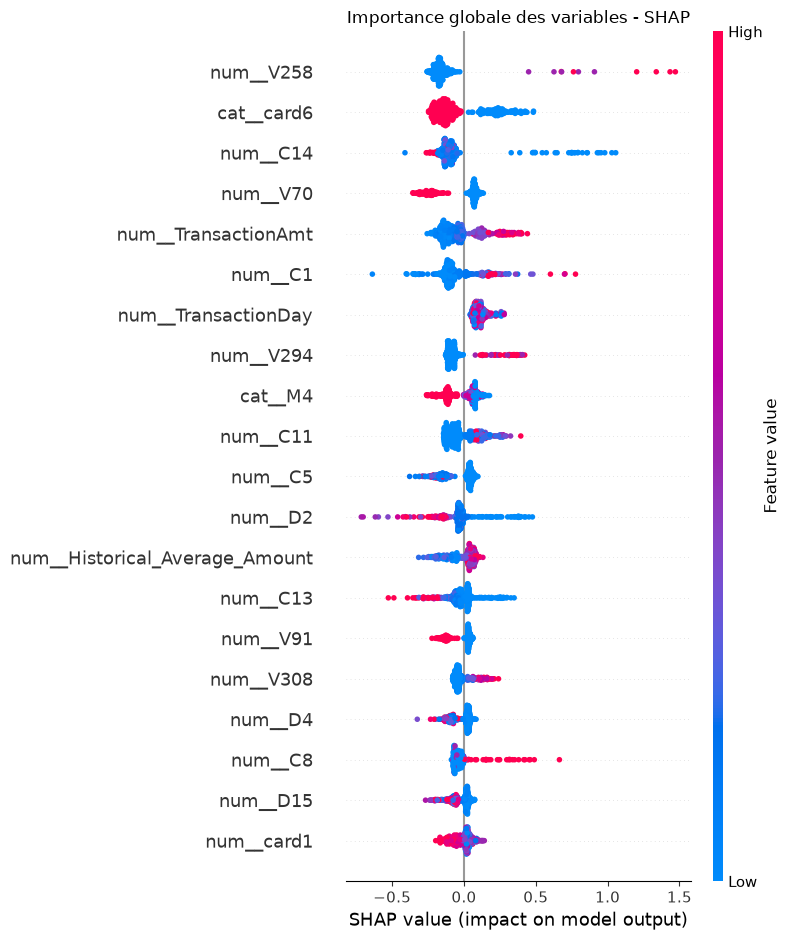

In [59]:
plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values.values,
    X_shap,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("Importance globale des variables - SHAP")
plt.tight_layout()

plt.savefig(
    "outputs/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
# Indice de la transaction la plus suspecte
local_index = int(np.argmax(y_val_proba))

# Extraire cette transaction
X_local = X_val_processed[local_index:local_index + 1]

# Calculer ses valeurs SHAP
local_explanation = explainer(X_local)

print("Indice de la transaction :", local_index)
print("Probabilité de fraude :", round(float(y_val_proba[local_index]), 4))
print("Seuil retenu :", best_threshold)

if y_val_array[local_index] == 1:
    print("Classe réelle : FRAUDE")
else:
    print("Classe réelle : NORMALE")

if y_val_proba[local_index] >= best_threshold:
    print("Décision du modèle : ALERTE FRAUDE")
else:
    print("Décision du modèle : TRANSACTION NORMALE")

Indice de la transaction : 63904
Probabilité de fraude : 0.9934
Seuil retenu : 0.45000000000000007
Classe réelle : FRAUDE
Décision du modèle : ALERTE FRAUDE


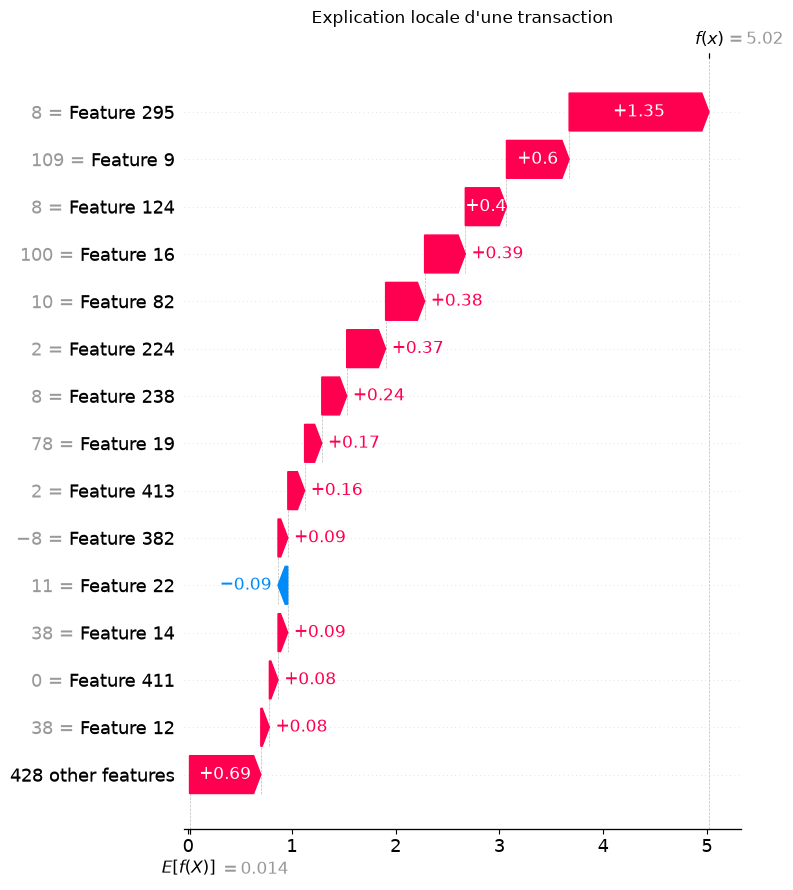

In [61]:
shap.plots.waterfall(
    local_explanation[0],
    max_display=15,
    show=False
)

plt.title("Explication locale d'une transaction")
plt.tight_layout()

plt.savefig(
    "outputs/shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [62]:
# Contributions SHAP de la transaction sélectionnée
local_values = local_explanation.values[0]

# Trier les contributions de la plus positive à la plus négative
top_indices = np.argsort(local_values)[::-1][:5]

print("===== PRINCIPALES RAISONS QUI AUGMENTENT LE RISQUE =====")

for index in top_indices:
    print(
        feature_names[index],
        "=> contribution SHAP :",
        round(float(local_values[index]), 4)
    )

===== PRINCIPALES RAISONS QUI AUGMENTENT LE RISQUE =====
num__V258 => contribution SHAP : 1.3476
num__C1 => contribution SHAP : 0.604
num__V87 => contribution SHAP : 0.3967
num__C8 => contribution SHAP : 0.3922
num__V45 => contribution SHAP : 0.3758


In [63]:
joblib.dump(
    explainer,
    "models/shap_explainer.pkl"
)

print("Explainer SHAP sauvegardé !")
print("Graphique global : outputs/shap_summary.png")
print("Graphique local : outputs/shap_waterfall.png")

Explainer SHAP sauvegardé !
Graphique global : outputs/shap_summary.png
Graphique local : outputs/shap_waterfall.png


In [64]:
import sys
import importlib.util
import os

print("Python :", sys.executable)
print("Streamlit installé :", importlib.util.find_spec("streamlit") is not None)

folders = [
    "pages",
    "src",
    "outputs",
    "models",
    "api"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("\nDossiers vérifiés ou créés.")

Python : C:\Users\DELL\Desktop\Azza_Khechine\FraudDetectionXAI\.venv\Scripts\python.exe
Streamlit installé : False

Dossiers vérifiés ou créés.


In [65]:
import sys

!{sys.executable} -m pip install streamlit plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/10.4 MB 3.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/10.4 MB 2.7 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/10.4 MB 3.2 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/10.4 MB 3.1 MB/s eta 0:00:03
   --------------

In [66]:
import sys
import importlib.util
import os

print("Python :", sys.executable)
print("Streamlit installé :", importlib.util.find_spec("streamlit") is not None)

folders = [
    "pages",
    "src",
    "outputs",
    "models",
    "api"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("\nDossiers vérifiés ou créés.")

Python : C:\Users\DELL\Desktop\Azza_Khechine\FraudDetectionXAI\.venv\Scripts\python.exe
Streamlit installé : True

Dossiers vérifiés ou créés.


In [67]:
import json
import os

os.makedirs("outputs", exist_ok=True)

metrics = {
    "XGBoost": {
        "PR-AUC": float(test_pr_auc),
        "ROC-AUC": float(test_roc_auc),
        "Precision": float(test_precision),
        "Recall": float(test_recall),
        "F2-score": float(test_f2),
        "MCC": float(test_mcc)
    }
}

with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Métriques sauvegardées dans outputs/metrics.json")

Métriques sauvegardées dans outputs/metrics.json


In [68]:
for _, row in comparison_df.iterrows():
    metrics[row["Modèle"]] = {
        "PR-AUC": float(row["PR-AUC"]),
        "ROC-AUC": float(row["ROC-AUC"])
    }

with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Comparaison des trois modèles sauvegardée !")

Comparaison des trois modèles sauvegardée !


In [69]:
import os

required_files = [
    "models/xgboost_model.pkl",
    "models/preprocessor.pkl",
    "models/isolation_forest.pkl",
    "models/lof_model.pkl",
    "models/anomaly_imputer.pkl",
    "models/anomaly_scaler.pkl",
    "models/anomaly_features.pkl",
    "models/business_config.pkl",
    "models/shap_explainer.pkl",
    "outputs/metrics.json",
    "outputs/shap_summary.png",
    "outputs/shap_waterfall.png"
]

print("Vérification des fichiers :\n")

for file in required_files:
    status = "OK" if os.path.exists(file) else "MANQUANT"
    print(status, "-", file)

Vérification des fichiers :

OK - models/xgboost_model.pkl
OK - models/preprocessor.pkl
OK - models/isolation_forest.pkl
OK - models/lof_model.pkl
OK - models/anomaly_imputer.pkl
OK - models/anomaly_scaler.pkl
OK - models/anomaly_features.pkl
OK - models/business_config.pkl
OK - models/shap_explainer.pkl
OK - outputs/metrics.json
OK - outputs/shap_summary.png
OK - outputs/shap_waterfall.png


In [70]:

import json
import os

os.makedirs("outputs", exist_ok=True)

# 1. Résultats finaux de XGBoost sur le jeu de TEST
test_metrics = {
    "PR-AUC": float(test_pr_auc),
    "ROC-AUC": float(test_roc_auc),
    "Precision": float(test_precision),
    "Recall": float(test_recall),
    "F2-score": float(test_f2),
    "MCC": float(test_mcc)
}

# 2. Comparaison des trois modèles sur le jeu de VALIDATION
validation_comparison = {}

for _, row in comparison_df.iterrows():

    model_name = str(row["Modèle"])

    validation_comparison[model_name] = {
        "PR-AUC": float(row["PR-AUC"]),
        "ROC-AUC": float(row["ROC-AUC"])
    }

# 3. Organisation claire des résultats
results = {
    "test_metrics": {
        "XGBoost": test_metrics
    },
    "validation_comparison": validation_comparison,
    "evaluation_information": {
        "test_threshold": 0.45,
        "validation_comparison_sample_size": 20000,
        "comparison_note": (
            "Les modèles non supervisés ont été entraînés "
            "sur des échantillons et des variables différents."
        )
    }
}

# 4. Sauvegarde
with open("outputs/metrics.json", "w", encoding="utf-8") as file:
    json.dump(results, file, indent=4)

print("Fichier metrics.json corrigé avec succès.")
print("\nRésultats XGBoost sur TEST :")
print(test_metrics)

print("\nComparaison sur VALIDATION :")
for model, values in validation_comparison.items():
    print(model, values)


Fichier metrics.json corrigé avec succès.

Résultats XGBoost sur TEST :
{'PR-AUC': 0.4569661166140316, 'ROC-AUC': 0.8807725088993832, 'Precision': 0.13633404227614046, 'Recall': 0.7728838582677166, 'F2-score': 0.39966916910548417, 'MCC': 0.2752698887359051}

Comparaison sur VALIDATION :
XGBoost {'PR-AUC': 0.5397176549497739, 'ROC-AUC': 0.9118645784792431}
Isolation Forest {'PR-AUC': 0.05465093816329354, 'ROC-AUC': 0.6159047348906944}
LOF {'PR-AUC': 0.05231419025779572, 'ROC-AUC': 0.5413653247428598}


In [71]:
import json

with open("outputs/metrics.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("Clés principales :", list(data.keys()))

print("\nComparaison sur validation :")
print(data.get("validation_comparison", "CLÉ INTROUVABLE"))

Clés principales : ['test_metrics', 'validation_comparison', 'evaluation_information']

Comparaison sur validation :
{'XGBoost': {'PR-AUC': 0.5397176549497739, 'ROC-AUC': 0.9118645784792431}, 'Isolation Forest': {'PR-AUC': 0.05465093816329354, 'ROC-AUC': 0.6159047348906944}, 'LOF': {'PR-AUC': 0.05231419025779572, 'ROC-AUC': 0.5413653247428598}}


In [72]:
import joblib
from pathlib import Path

ROOT = Path.cwd()

fichiers = [
    "xgboost_model.pkl",
    "preprocessor.pkl",
    "business_config.pkl",
    "shap_explainer.pkl",
    "isolation_forest.pkl",
    "lof_model.pkl",
    "anomaly_imputer.pkl",
    "anomaly_scaler.pkl",
    "anomaly_features.pkl"
]

for nom in fichiers:
    chemin = ROOT / "models" / nom

    if chemin.exists():
        try:
            objet = joblib.load(chemin)
            print(f"OK : {nom} → {type(objet)}")
        except Exception as e:
            print(f"ERREUR : {nom} → {e}")
    else:
        print(f"INTROUVABLE : {nom}")

OK : xgboost_model.pkl → <class 'xgboost.sklearn.XGBClassifier'>
OK : preprocessor.pkl → <class 'sklearn.compose._column_transformer.ColumnTransformer'>
OK : business_config.pkl → <class 'dict'>
OK : shap_explainer.pkl → <class 'shap.explainers._tree.TreeExplainer'>
OK : isolation_forest.pkl → <class 'sklearn.ensemble._iforest.IsolationForest'>
OK : lof_model.pkl → <class 'sklearn.neighbors._lof.LocalOutlierFactor'>
OK : anomaly_imputer.pkl → <class 'sklearn.impute._base.SimpleImputer'>
OK : anomaly_scaler.pkl → <class 'sklearn.preprocessing._data.StandardScaler'>
OK : anomaly_features.pkl → <class 'list'>
